In [1]:
from utils import *
import numpy as np
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns

from sklearn.preprocessing import normalize

In [2]:
import pandas as pd

In [3]:
#expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2):

    #N = 10000
    #p = 10
    theta = 2*np.random.rand(p)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    #x = np.random.rand(p*N).reshape(N, p)
    f = x @ theta
    p = expit(f)
    y = np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [4]:
ss = 2
algos_dict = {
  #'Random': [logistic_solver, {}, 20, 'Random', 'y'],
  'Greedy_test_1': [Greedy_test_1, {'k':ss}, 10, 'Greedy_test_1', 'y'],  
  #'Greedy_test_2': [Greedy_test_2, {}, 20, 'Greedy_test_2', 'b'],  
  'Greedy_logistic': [Greedy_logistic, {'k':ss}, 10, 'Greedy_logistic', 'red'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'darkblue'],
  #'Greedy_bernoulli_bayes': [Greedy_bernoulli_bayes, {'k':ss}, 20, 'Greedy_bernoulli_bayes', 'darkgreen'],
  #'Greedy_bernoulli_freq': [Greedy_bernoulli_freq, {'k':ss}, 20, 'Greedy_bernoulli_freq', 'lightgreen'],
  #'TS_bernoulli': [TS_bernoulli, {}, 20, 'TS_bernoulli', 'm'],
  #'Greedy_logistic_search': [Greedy_logistic_search, {'k':1}, 20, 'Greedy_logistic_search', 'y']
    
}

In [32]:
x, y, theta = gen_data(30, 2)
#x_1 = .1*x[np.random.choice(300,700, replace=True),:] +.12*theta
#x = np.concatenate([x,x_1])

n_row, n_col = x.shape[0], 1
_, n_desc =  x.shape
cutoff = n_desc
T = 1000
prob_dict = {
        "m": n_row,
        "noise": 0.01,
        "d": cutoff,
        "theta": theta,
      }
prob = logistic_discover(**prob_dict)
#x = x - x.mean(0)
#x = normalize(x, axis=0, norm='l2')
prob.x = x.copy()
#prob.y = y.copy()
#t_prob = deepcopy(prob)

reg_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
#tau_list = {algo:[] for algo in algos_dict}
for trial_idx in trange(100):
            # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd = solver.run(T)[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
        reg_list[algo].append(reg)
        rwd_list[algo].append(np.cumsum(rwd))
                #tau_list[algo].append(tau)

        #for algo in algos_dict:
        #algo_label = algos_dict[algo][3]
        #algo_style = algos_dict[algo][4]

100%|█████████████████████████████████████████| 100/100 [00:36<00:00,  2.71it/s]


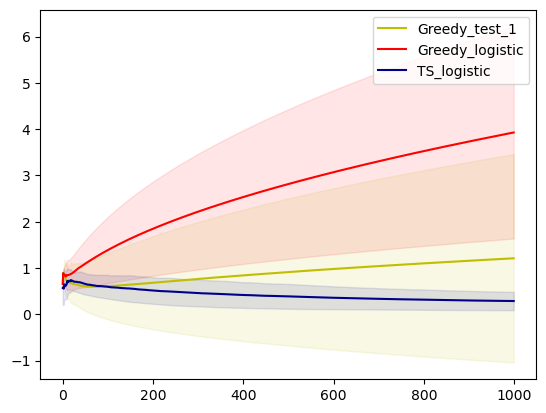

In [33]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

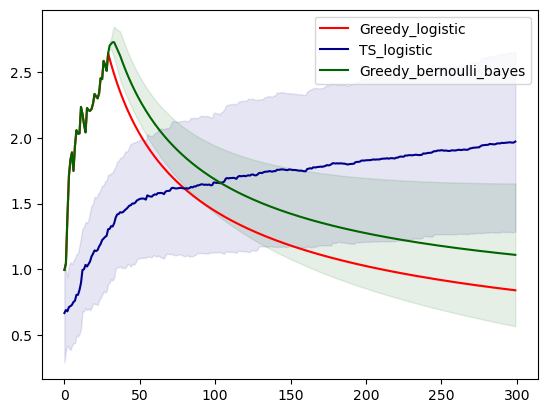

In [8]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:300]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:300]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

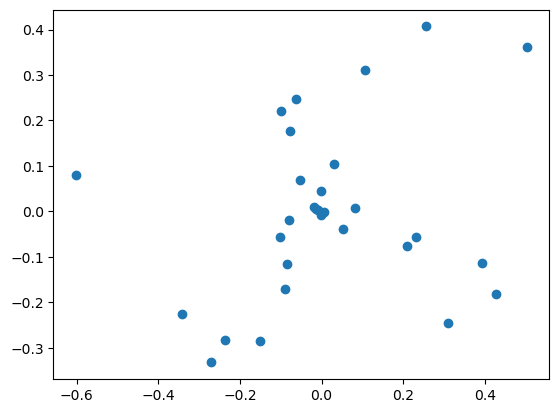

In [9]:
#plt.scatter(x_1[:,0],x_1[:,1])
plt.scatter(x[:,0],x[:,1])

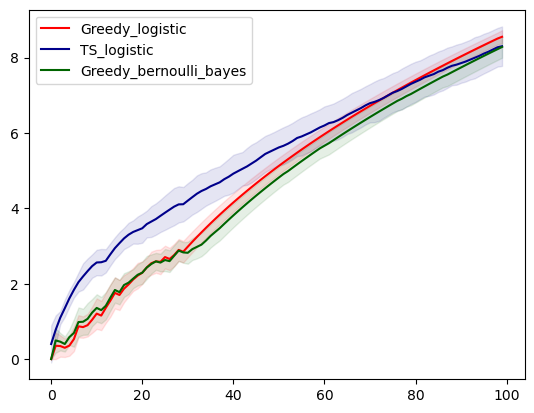

In [10]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(rwd_list[algo], axis = 0)[:100]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(rwd_list[algo], axis = 0)[:100]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [274]:
x, y,theta = gen_data(M, 50)
x_1 = .15*x[np.random.choice(300, 100, replace=False),:] +.1*theta
x = np.concatenate([x, x_1])
plt.scatter(x[:,0],x[:,1])

In [4]:
ss = 1
algos_dict = {
  #'Random': [logistic_solver, {}, 20, 'Random', 'y'],
  'Greedy_logistic': [Greedy_logistic, {'k':ss}, 20, 'Greedy_logistic', 'darkred'],
  'Greedy_logistic_search': [Greedy_logistic_search, {'k':1}, 20, 'Greedy_logistic_search', 'red'],
  'TS_logistic': [TS_logistic, {}, 20, 'TS_logistic', 'darkblue'],
  'TS_logistic_search': [TS_logistic_search, {}, 20, 'TS_logistic_search', 'blue'],
  #'Greedy_bernoulli': [Greedy_bernoulli_bayes, {'k':ss}, 20, 'Greedy_bernoulli_bayes', 'orange'],
  #'Greedy_bernoulli_freq': [Greedy_bernoulli_freq, {'k':ss}, 20, 'Greedy_bernoulli_freq', 'lightgreen'],
  #'TS_bernoulli': [TS_bernoulli, {}, 20, 'TS_bernoulli', 'lightblue'],
  
    
}

In [10]:

#prob.y = y.copy()
#t_prob = deepcopy(prob)


#tau_list = {algo:[] for algo in algos_dict}
n_arms = 100
T = 1000
reg_M_list = {M:[] for M in range(n_arms,n_arms +1)}
for M in trange(n_arms,n_arms+1):
    reg_list = {algo:[] for algo in algos_dict}
    rwd_list = {algo:[] for algo in algos_dict}
    for trial_idx in trange(10):
        x, y, theta = gen_data(M, 2)
        #x_1 = .01*x[np.random.choice(n_arms, T-n_arms, replace=True),:] +.12*theta
        x_1 = x[[np.argmax(x @ theta)] *(T-n_arms), :]
        x_search = np.concatenate([x, x_1])
        
        x = x - x.mean(0)
        x = normalize(x, axis=0, norm='l2')

        x_search = x_search - x_search.mean(0)
        x_search = normalize(x_search, axis=0, norm='l2')
            
        #prob.x = x.copy()
                # print(prob.x)
        for algo, algo_setup in algos_dict.items():
            #print(algo)
            #
            
            if algo[-6:] == 'search':
                #t_prob.x = x_search.copy()
                n_row, n_col = x_search.shape[0], 1
                _, n_desc =  x_search.shape
                cutoff = n_desc
                prob_dict = {
                        "m": n_row,
                        "noise": 0.01,
                        "d": cutoff,
                        "theta": theta,
                      }
                prob = logistic_discover(**prob_dict)
                prob.x = x_search.copy()
                #print(n_row)
            else:
                n_row, n_col = x.shape[0], 1
                _, n_desc =  x.shape
                cutoff = n_desc
                prob_dict = {
                        "m": n_row,
                        "noise": 0.01,
                        "d": cutoff,
                        "theta": theta,
                      }
                prob = logistic_discover(**prob_dict)
                prob.x = x.copy()
            
            t_prob = deepcopy(prob)
            algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                            # print(algo_func)
            if not trial_idx < algo_N_trials:
                continue
            solver = algo_func(t_prob, **algo_params)
            reg, rwd = solver.run(T)[:2]
                    #act_list[algo].append(getattr(solver, "logistic_discover"))
                    #act_list[algo].append(t_prob.actions)
                    # print(prob.rewards)
            reg_list[algo].append(reg)
            rwd_list[algo].append(np.cumsum(rwd))
                    #tau_list[algo].append(tau)

            #for algo in algos_dict:
            #algo_label = algos_dict[algo][3]
            #algo_style = algos_dict[algo][4]
    reg_M_list[M] = reg_list

100%|█████████████████████████████████████████████| 1/1 [01:09<00:00, 69.05s/it]


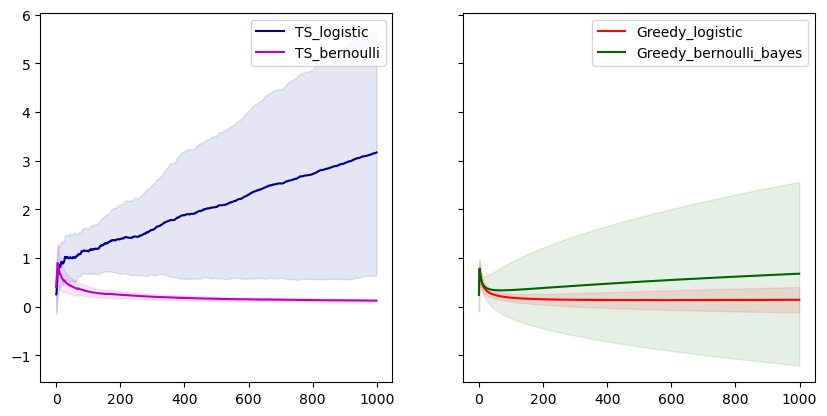

In [92]:
alpha = 0.5
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
#fig.set_figheight(150)
fig.set_figwidth(10)
#fig.tight_layout(pad=2.0)
for algo in algos_dict:
    
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    
    if algo[:2] == 'TS':
        
        
        ax[0].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[0].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[0].legend()
    
    else:
        ax[1].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[1].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[1].legend()

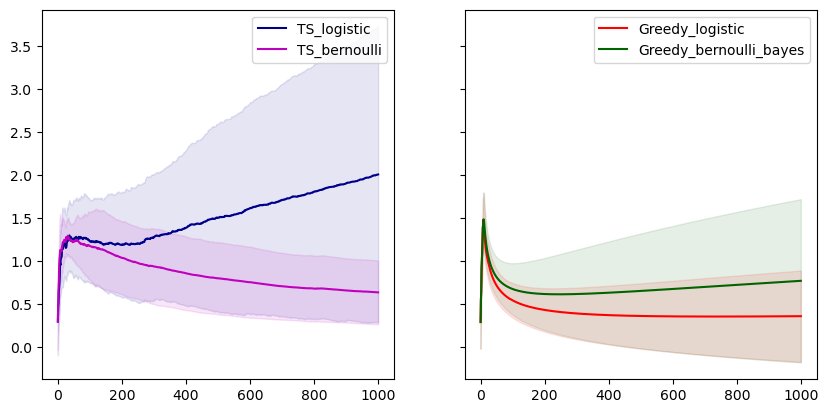

In [89]:
alpha = 0.5
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
#fig.set_figheight(150)
fig.set_figwidth(10)
#fig.tight_layout(pad=2.0)
for algo in algos_dict:
    
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    
    if algo[:2] == 'TS':
        
        
        ax[0].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[0].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[0].legend()
    
    else:
        ax[1].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[1].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[1].legend()

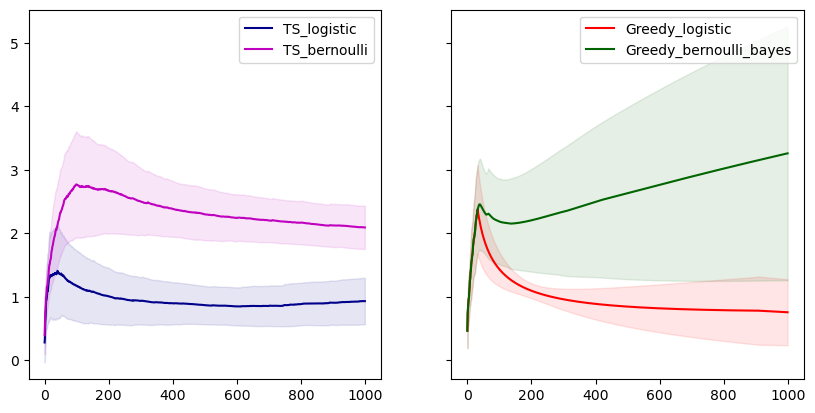

In [83]:
alpha = 0.5
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
#fig.set_figheight(150)
fig.set_figwidth(10)
#fig.tight_layout(pad=2.0)
for algo in algos_dict:
    
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    
    if algo[:2] == 'TS':
        
        
        ax[0].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[0].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[0].legend()
    
    else:
        ax[1].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[1].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[1].legend()

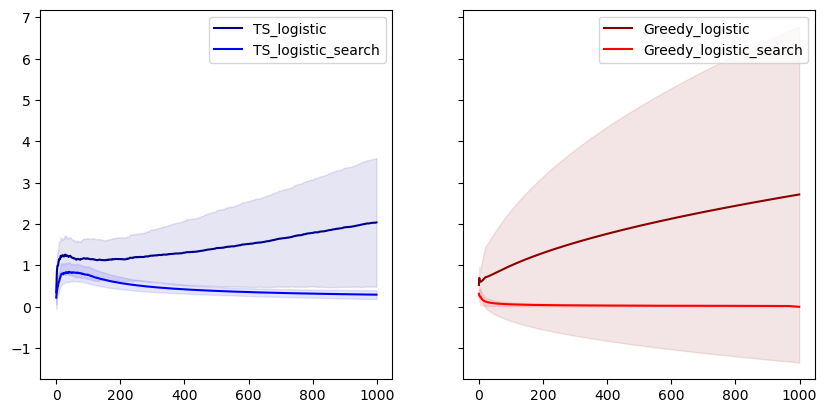

In [57]:
alpha = 0.5
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
#fig.set_figheight(150)
fig.set_figwidth(10)
#fig.tight_layout(pad=2.0)
for algo in algos_dict:
    
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    
    if algo[:2] == 'TS':
        
        
        ax[0].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[0].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[0].legend()
    
    else:
        ax[1].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[1].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[1].legend()

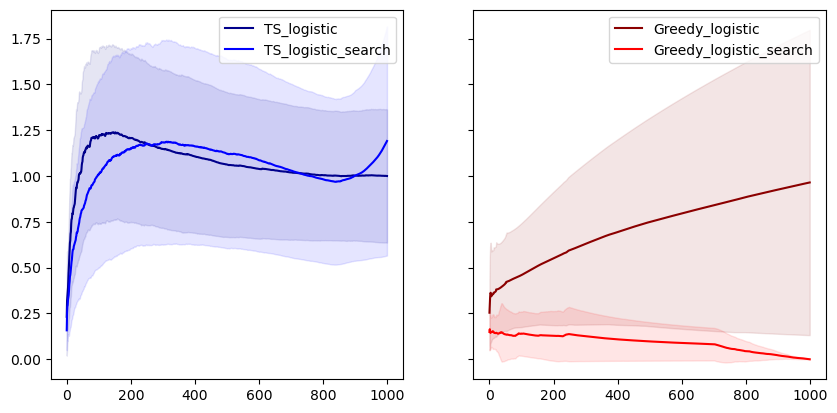

In [53]:
alpha = 0.5
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
#fig.set_figheight(150)
fig.set_figwidth(10)
#fig.tight_layout(pad=2.0)
for algo in algos_dict:
    
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    
    if algo[:2] == 'TS':
        
        
        ax[0].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[0].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[0].legend()
    
    else:
        ax[1].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[1].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[1].legend()

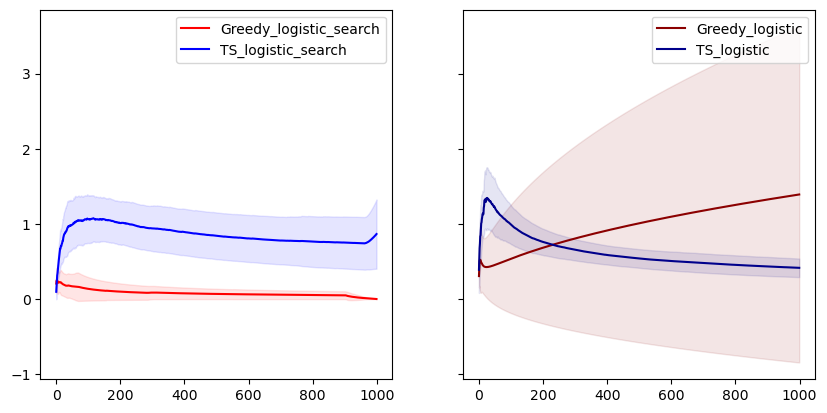

In [15]:
alpha = 0.5
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
#fig.set_figheight(150)
fig.set_figwidth(10)
#fig.tight_layout(pad=2.0)
for algo in algos_dict:
    
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    
    if algo[-1] == 'h':
        
        
        ax[0].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[0].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[0].legend()
    
    else:
        ax[1].plot(range(y_.shape[0]), y_,
                      algo_style, label=algo_label)
        ax[1].fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

        ax[1].legend()
#plt.ylim(0,1)

In [33]:
reg_M_mean = np.zeros((35, T))
reg_M_sd = np.zeros((35, T))
for i, M in enumerate(range(5,40)):
    reg_M_mean[i,:] = np.mean(reg_M_list[M]['Greedy_logistic'] , axis = 0) / np.power((np.ones(T)).cumsum(),0.5)
    reg_M_sd[i,:] = np.std(reg_M_list[M]['Greedy_logistic'] , axis = 0) / np.power((np.ones(T)).cumsum(),0.5)
        #reg_M_mean[i,:] = np.mean(reg_M_list[M]['Greedy_logistic'] , axis = 0) / np.power((np.ones(T)).cumsum(),.5)
        
reg_M_mean_df = pd.DataFrame(reg_M_mean)
reg_M_mean_df['index'] = range(5,40)
reg_M_mean_df = reg_M_mean_df.set_index('index')

sns.heatmap(reg_M_mean_df)

KeyError: 5

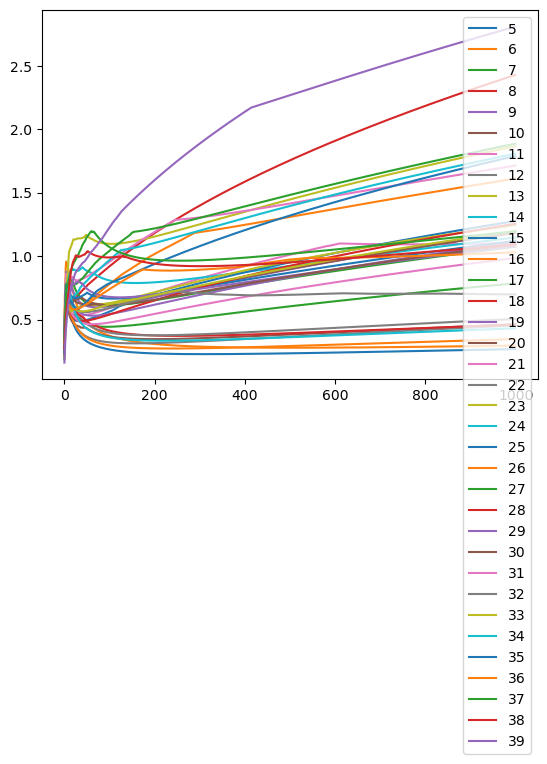

In [272]:
for i, M in enumerate(range(5,40)):
    plt.plot(reg_M_mean[i,:], label=M)
    #plt.fill_between(range(T), (reg_M_mean[i,:]-reg_M_sd[i,:]), (reg_M_mean[i,:]+reg_M_sd[i,:]), alpha=.1)
plt.legend()

<AxesSubplot: ylabel='index'>

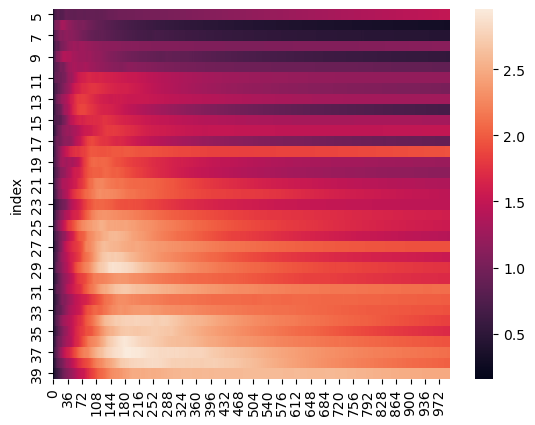

In [268]:
reg_M_mean = np.zeros((35, T))
reg_M_sd = np.zeros((35, T))
for i, M in enumerate(range(5,40)):
    reg_M_mean[i,:] = np.mean(reg_M_list[M]['Greedy_bernoulli_freq'] , axis = 0) / np.power((np.ones(T)).cumsum(),0.5)
    reg_M_sd[i,:] = np.std(reg_M_list[M]['Greedy_bernoulli_freq'] , axis = 0) / np.power((np.ones(T)).cumsum(),0.5)
        #reg_M_mean[i,:] = np.mean(reg_M_list[M]['Greedy_logistic'] , axis = 0) / np.power((np.ones(T)).cumsum(),.5)
        
reg_M_mean_df = pd.DataFrame(reg_M_mean)
reg_M_mean_df['index'] = range(5,40)
reg_M_mean_df = reg_M_mean_df.set_index('index')

sns.heatmap(reg_M_mean_df)

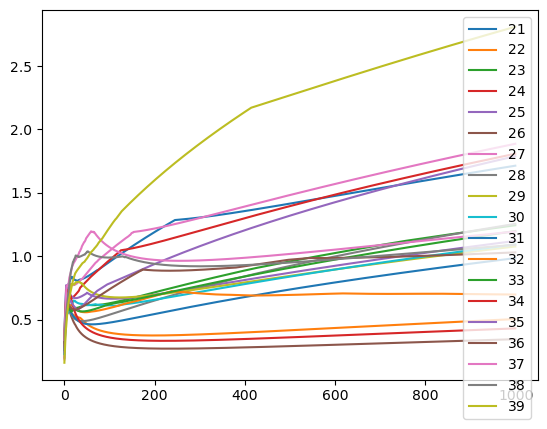

In [292]:
for i, M in enumerate(range(5,40)):
    if i > 15:
        plt.plot(reg_M_mean[i,:], label=M, c=)
    #plt.fill_between(range(T), (reg_M_mean[i,:]-reg_M_sd[i,:]), (reg_M_mean[i,:]+reg_M_sd[i,:]), alpha=.1)
plt.legend()

<AxesSubplot: ylabel='index'>

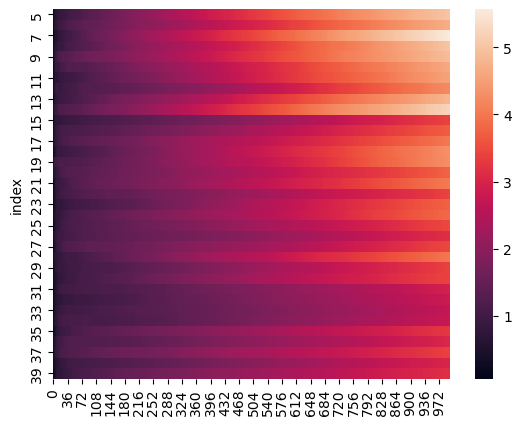

In [267]:
reg_M_mean = np.zeros((35, T))
reg_M_sd = np.zeros((35, T))
for i, M in enumerate(range(5,40)):
    for algo in algos_dict:
        reg_M_mean[i,:] = np.mean(reg_M_list[M]['TS_logistic'] , axis = 0) / np.power((np.ones(T)).cumsum(),.5)
        reg_M_sd[i,:] = np.std(reg_M_list[M]['TS_logistic'] , axis = 0) / np.power((np.ones(T)).cumsum(),.5)
        
reg_M_mean_df = pd.DataFrame(reg_M_mean)
reg_M_mean_df['index'] = range(5,40)
reg_M_mean_df = reg_M_mean_df.set_index('index')
sns.heatmap(reg_M_mean_df)

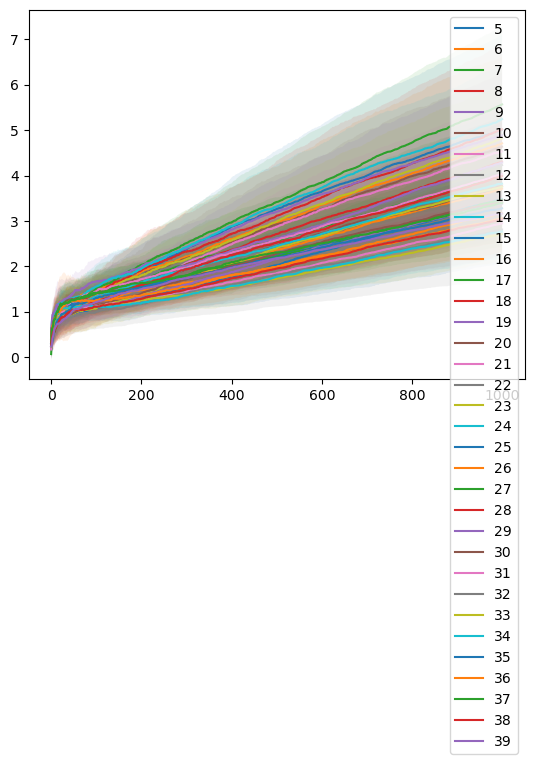

In [260]:
for i, M in enumerate(range(5,40)):
    plt.plot(reg_M_mean[i,:], label=M)
    plt.fill_between(range(T), (reg_M_mean[i,:]-reg_M_sd[i,:]), (reg_M_mean[i,:]+reg_M_sd[i,:]), alpha=.1)
plt.legend()

ValueError: operands could not be broadcast together with shapes (300,) (1000,) 

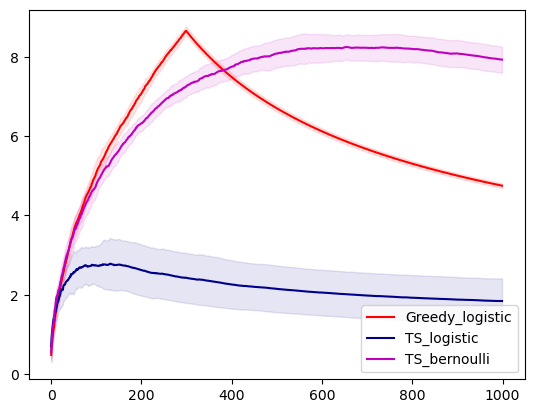

In [141]:
alpha = .5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]/ np.power((np.ones(T)).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:T]/ np.power((np.ones(T)).cumsum(), alpha)
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [120]:
x, y,theta = gen_data(M, 2)
expit(x @ theta).mean()

0.5985686507976565

In [282]:
ss = 1
algos_dict = {
  #'Random': [logistic_solver, {}, 20, 'Random', 'y'],
  'Greedy_logistic': [Greedy_logistic, {'k':ss}, 20, 'Greedy_logistic', 'red'],
  'TS_logistic': [TS_logistic, {}, 20, 'TS_logistic', 'darkblue'],
  #'Greedy_bernoulli_bayes': [Greedy_bernoulli_bayes, {'k':ss}, 20, 'Greedy_bernoulli_bayes', 'darkgreen'],
  'Greedy_bernoulli_freq': [Greedy_bernoulli_freq, {'k':ss}, 20, 'Greedy_bernoulli_freq', 'lightgreen'],
  #'TS_bernoulli': [TS_bernoulli, {}, 20, 'TS_bernoulli', 'm'],
  'Greedy_logistic_search': [Greedy_logistic_search, {'k':1}, 20, 'Greedy_logistic_search', 'y']
    
}

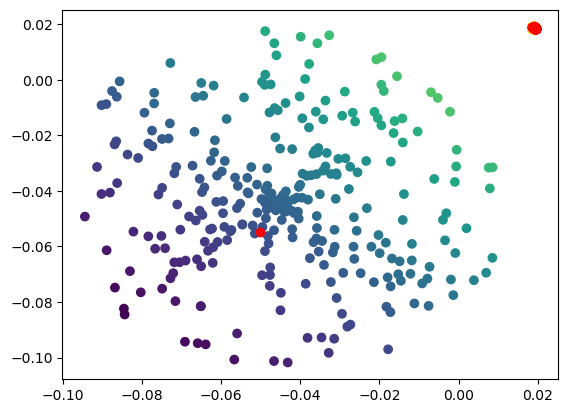

In [60]:
plt.scatter(x[:, 0], x[:, 1], c=expit(x @ theta))
n = 300
plt.scatter(x[solver.prob.actions[:n], 0], 
            x[solver.prob.actions[:n], 1], 
            c='r')

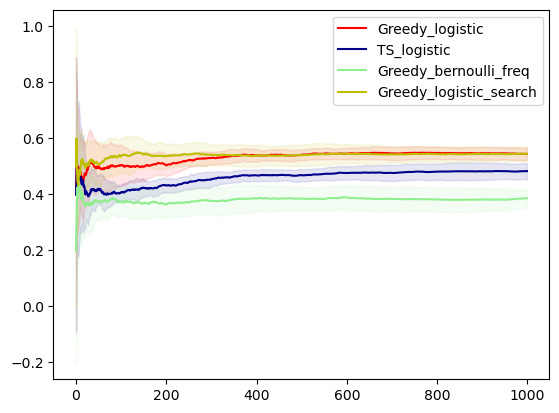

In [309]:
alpha = 1
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(rwd_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(rwd_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [22]:
l = np.random.rand(10)

In [26]:
np.argsort(l)[::-1][:2]

array([2, 5])

In [21]:
ss = 0
algos_dict = {
    'TS_linear': [TS_linear, {}, 100, 'TS_linear', 'y'],  
    'Greedy_linear': [Greedy_linear, {}, 100, 'Greedy_linear', 'g'],  
  'Greedy_test_2': [Greedy_test_2, {'k':ss}, 100, 'Greedy_test_2', 'b'], 
    'Greedy_Frechet': [Greedy_Frechet, {'k':ss, 'dim':4}, 100, 'Greedy_Frechet', 'r'], 
    #'Greedy_test_linear_kernel': [Greedy_test_linear_kernel, {'k':ss, 
    #                                                          'degree':5,
    #                                                          'kernel':'poly',
    #                                                          'sig_kernel':.1,
    #                                                          'kernel_dim':10}, 100, 'Greedy_test_linear_kernel', 'r'], 
    
}

In [26]:
ss = 5
algos_dict = {
    'Greedy_test_1': [Greedy_test_1, {'k':ss}, 10, 'Greedy_test_1', 'b'],
  'Greedy_logistic': [Greedy_logistic, {'k':ss}, 10, 'Greedy_logistic', 'g'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'y'],
    'Greedy_logistic_Frechet': [Greedy_logistic_Frechet, {'k':ss, 'dim':5}, 10, 'Greedy_logistic_Frechet', 'r'],
    
}

In [29]:
M = 10
T = 100
reg_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
for trial_idx in trange(5):
    x, y, theta = gen_data(M, 2)
        #x_1 = .01*x[np.random.choice(n_arms, T-n_arms, replace=True),:] +.12*theta
    #x_1 = x[[np.argmax(x @ theta)] *(T-M), :]
    #x_search = np.concatenate([x, x_1])
        
    #x = x - x.mean(0)
    #x = normalize(x, axis=0, norm='l2')

    #x_search = x_search - x_search.mean(0)
    #x_search = normalize(x_search, axis=0, norm='l2')
            
        #prob.x = x.copy()
                # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        #print(algo)
            #
        n_row, n_col = x.shape[0], 1
        _, n_desc =  x.shape
        cutoff = n_desc
        prob_dict = {
                    "m": n_row,
                    "noise": 0.01,
                    "d": cutoff,
                    "theta": theta,
                    }
        prob = logistic_discover(**prob_dict)
        prob.x = x.copy()
            
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                            # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd = solver.run(T)[:2]
                    #act_list[algo].append(getattr(solver, "logistic_discover"))
                    #act_list[algo].append(t_prob.actions)
                    # print(prob.rewards)
        reg_list[algo].append(reg)
        rwd_list[algo].append(np.cumsum(rwd))
                    #tau_list[algo].append(tau)

            #for algo in algos_dict:
            #algo_label = algos_dict[algo][3]
            #algo_style = algos_dict[algo][4]


  0%|                                                     | 0/5 [00:00<?, ?it/s]/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/exploring_greedy/utils.py:24: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
 40%|██████████████████                           | 2/5 [00:02<00:04,  1.40s/it]/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/exploring_greedy/utils.py:24: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
 80%|████████████████████████████████████         | 4/5 [00:05<00:01,  1.41s/it]/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/exploring_greedy/utils.py:24: RuntimeWarning: overflow encountered in exp
  expit = lambda x: 1/(1+np.exp(-x))
100%|█████████████████████████████████████████████| 5/5 [00:07<00:00,  1.43s/it]


In [10]:
solver.mu_t

array([0.        , 0.33333333, 0.18157808, 0.32398543, 0.33996459,
       0.34717627, 0.08995027, 0.        , 0.10220453, 0.04402042,
       0.12051821, 0.08577866, 0.10514203, 0.11618374, 0.33493028,
       0.        , 0.        , 0.117927  , 0.08874839, 0.09172868,
       0.17646405, 0.        , 0.05549475, 0.4637827 , 0.22793894,
       0.03977507, 0.10815101, 0.07424916, 0.        , 0.1741738 ])

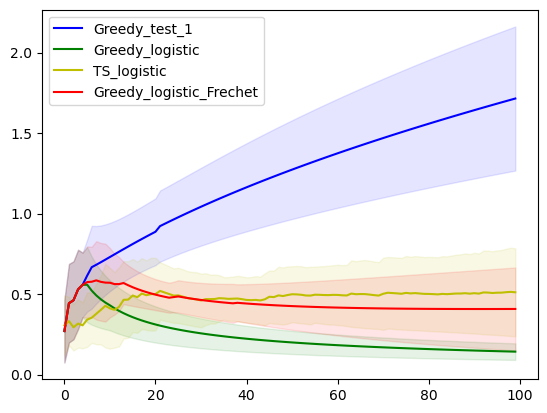

In [30]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

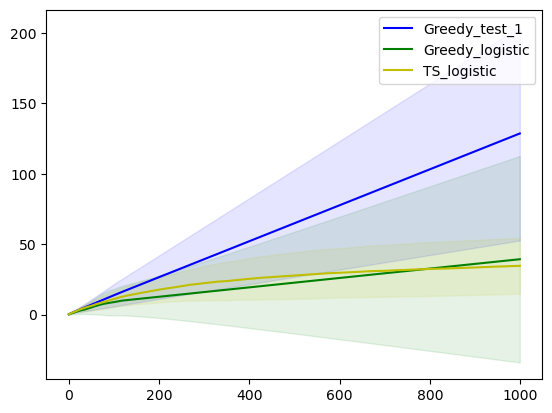

In [19]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [51]:
kernel = 1.0 * RBF(1.0)

In [103]:
np.setdiff1d(range(5), [1,3])

array([0, 2, 4])

In [100]:
kernel(x)[[1,3,4,5]]

array([[0.9202724 , 1.        , 0.92574743, 0.83416334, 0.8465256 ,
        0.88935604, 0.84030335, 0.94947742, 0.91439963, 0.9383007 ,
        0.8937517 , 0.92876821, 0.89544036, 0.73905106, 0.92830628,
        0.94331969, 0.97458183, 0.76367218, 0.92226536, 0.7846395 ,
        0.86138224, 0.77002704, 0.99484898, 0.87680918, 0.76954422,
        0.89018562, 0.89289878, 0.95153674, 0.97621006, 0.93577669],
       [0.97448671, 0.83416334, 0.96302486, 1.        , 0.98123905,
        0.99216809, 0.9815614 , 0.93874381, 0.9807801 , 0.96219268,
        0.9894367 , 0.9730478 , 0.94148811, 0.8676125 , 0.97683211,
        0.96506203, 0.81684635, 0.9687724 , 0.95953933, 0.94213478,
        0.97192308, 0.86143539, 0.88180948, 0.92208461, 0.98884995,
        0.9927746 , 0.95128527, 0.91486815, 0.92929918, 0.90733702],
       [0.98476027, 0.8465256 , 0.93264371, 0.98123905, 1.        ,
        0.98707565, 0.99991681, 0.91103375, 0.98485788, 0.97578381,
        0.98931704, 0.95469262, 0.98349458, 0.

In [27]:
np.min(np.abs(x @ x.T / 2))

5.042067205022604e-06

In [24]:
import sklearn
np.min(np.abs(sklearn.metrics.pairwise.polynomial_kernel(x, degree=1, coef0=0)))

5.042067205022604e-06

In [63]:
kernel(np.array([1,0,0,1]).reshape(2,2))

array([[1.        , 0.36787944],
       [0.36787944, 1.        ]])